# 03 - Patch model

This notebook trains a model that looks at small overlapping pieces of each pill image instead of the whole image. The pieces are cut from the same 256 × 256 images used by the whole-image model, so the only difference is whole image versus patch. It also turns the errors from those pieces into a heatmap showing where a pill looks defective.

## Steps

1. Load the same `split.csv` used by the whole-image notebook. Give each image its training or validation label before cutting any patches.
2. Resize each image to 256 × 256 in the same way as notebook 02. Then cut overlapping 128 × 128 patches from those resized images. Pick one step size and use it for every image.
3. Decide what to do with patches that are mostly background, and use that same rule for training and validation.
4. If the patches are augmented, use only small shifts and small brightness changes. Do not change the colors, and do not flip the images. Color changes can hide a color defect, and flips mirror the printed marking.
5. Train a convolutional autoencoder on patches from normal training images only.
6. Save the trained weights in `outputs/checkpoints/`, along with the patch size, step size, and background rule.
7. Put each patch error back in its place on the 256 × 256 image, and combine the overlapping patches into one heatmap per image.
8. Do not read test labels or defect masks. Keep the validation heatmaps for notebook 04, which will score both models in the same way.


### 1. Set up

Load the tools this notebook needs and find the project folder. The pill photos, the shared split, and the place for saved results all live there.

The computer will use its normal processor. No graphics chip is required.

In [1]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

# Find the project folder whether this notebook is opened from the project
# folder or from the notebooks folder.
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "split.csv").exists():
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data" / "pill"
SPLIT_FILE = PROJECT_DIR / "split.csv"
CHECKPOINT_DIR = PROJECT_DIR / "outputs" / "checkpoints"
FIGURE_DIR = PROJECT_DIR / "outputs" / "figures"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Same picture size as the whole image model.
IMAGE_SIZE = 256
# Each patch is a square piece of that picture.
PATCH_SIZE = 128
# The next patch starts 64 pixels later, so neighboring patches overlap by half.
STRIDE = 64

# A patch is treated as empty background only when it is both dark and flat.
# The same two cutoffs are used for training and validation.
BACKGROUND_BRIGHTNESS = 0.08
BACKGROUND_SPREAD = 0.05

# This PC has no graphics chip, so training runs on the normal processor.
device = torch.device("cpu")

print("Project folder:", PROJECT_DIR)
print("Dataset found:", DATA_DIR.exists())
print("Split file found:", SPLIT_FILE.exists())
print("Device:", device)

Project folder: /Users/morgancook/Documents/SYRACUSE UNIVERSITY/Fall 2026/IST 691/FinalProject_Pills/pill-defect-detection
Dataset found: True
Split file found: True
Device: cpu


### 2. Load the shared split

Read `split.csv` from notebook 01. Each photo already has a training or validation label. Patches are cut only after that label is known, and a patch keeps the label of its photo.

This notebook uses normal pills only. It does not open the test photos or the defect masks.

In [2]:
split_df = pd.read_csv(SPLIT_FILE)
train_paths = split_df.loc[split_df["split"] == "train", "relative_path"].tolist()
val_paths = split_df.loc[split_df["split"] == "val", "relative_path"].tolist()

all_paths = train_paths + val_paths
outside_training = [path for path in all_paths if not path.startswith("train/good/")]
if outside_training:
    raise RuntimeError("The split includes a photo that is not a normal training pill.")
if not train_paths or not val_paths:
    raise RuntimeError("The split needs both training and validation photos.")

print("Training photos:", len(train_paths))
print("Validation photos:", len(val_paths))

Training photos: 214
Validation photos: 53


### 3. Resize, then cut patches

Each photo is resized to 256 by 256 in the same way as notebook 02. The color photo is kept, and the pixel values are scaled from 0 to 1.

Patches are then cut from that resized photo, not from the original 800 by 800 photo. A patch is 128 by 128. The step size is 64 pixels, so the next patch overlaps the previous one by half. Every photo uses this same step size.

In [3]:
# This is the same resize used by the whole image model.
resize_to_model = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])


def load_resized(relative_path):
    # Open one pill photo and make it 256 by 256.
    image = Image.open(DATA_DIR / relative_path).convert("RGB")
    return resize_to_model(image)


def patch_positions():
    # Top left corner of every patch on the 256 by 256 photo.
    positions = []
    limit = IMAGE_SIZE - PATCH_SIZE + 1
    for top in range(0, limit, STRIDE):
        for left in range(0, limit, STRIDE):
            positions.append((top, left))
    return positions


POSITIONS = patch_positions()
print("Patches cut from one photo before the background check:", len(POSITIONS))

Patches cut from one photo before the background check: 9


### 4. Skip empty background

The pill does not fill the whole photo, so some patches are only the dark empty area around it. A patch is skipped when it is dark and almost one flat color. A patch with markings or edges is kept.

Training and validation use this same rule. Skipped patches are not used to teach the model, and they are not used in the validation error.

In [4]:
def is_background(patch):
    # Average the three colors, then measure brightness and how much the pixels vary.
    gray = patch.mean(dim=0)
    brightness = gray.mean().item()
    spread = gray.std().item()
    return brightness < BACKGROUND_BRIGHTNESS and spread < BACKGROUND_SPREAD


def collect_patches(relative_paths):
    # Return the kept patches and how many empty patches were skipped.
    kept = []
    skipped = 0
    for relative_path in relative_paths:
        image = load_resized(relative_path)
        for top, left in POSITIONS:
            patch = image[:, top:top + PATCH_SIZE, left:left + PATCH_SIZE]
            if is_background(patch):
                skipped += 1
            else:
                kept.append(patch)
    if not kept:
        raise RuntimeError("Every patch was marked as background. Check the background cutoffs.")
    return torch.stack(kept), skipped


train_patches, train_skipped = collect_patches(train_paths)
val_patches, val_skipped = collect_patches(val_paths)

print("Training patches kept:", len(train_patches))
print("Training patches skipped:", train_skipped)
print("Validation patches kept:", len(val_patches))
print("Validation patches skipped:", val_skipped)

Training patches kept: 1926
Training patches skipped: 0
Validation patches kept: 477
Validation patches skipped: 0


### 5. Small changes for training only

Training patches can be shifted a little, and they can be made slightly lighter or darker. The same change is applied to every color, so the color of the pill does not change. Patches are not flipped, because a flip would mirror the printed marking.

Validation patches are left unchanged. The model is judged on the real photos, not on altered ones.

In [5]:
class PatchSet(Dataset):
    def __init__(self, patches, alter):
        self.patches = patches
        self.alter = alter

    def __len__(self):
        return len(self.patches)

    def __getitem__(self, index):
        patch = self.patches[index]
        if not self.alter:
            return patch

        # Move the patch by up to 6 pixels. Empty space is filled with black.
        limit = 6
        dx = random.randint(-limit, limit)
        dy = random.randint(-limit, limit)
        shifted = torch.zeros_like(patch)
        height, width = patch.shape[1], patch.shape[2]
        source_top = max(0, -dy)
        source_left = max(0, -dx)
        dest_top = max(0, dy)
        dest_left = max(0, dx)
        copy_height = height - abs(dy)
        copy_width = width - abs(dx)
        shifted[:, dest_top:dest_top + copy_height, dest_left:dest_left + copy_width] = patch[
            :,
            source_top:source_top + copy_height,
            source_left:source_left + copy_width,
        ]

        # Change lightness only. All three colors are multiplied by the same amount.
        lightness = random.uniform(0.9, 1.1)
        return torch.clamp(shifted * lightness, 0, 1)


train_loader = DataLoader(PatchSet(train_patches, alter=True), batch_size=32, shuffle=True)
val_loader = DataLoader(PatchSet(val_patches, alter=False), batch_size=32, shuffle=False)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 61
Validation batches: 15


### 6. Build the patch model

The model is a convolutional autoencoder, the same kind of model used for the whole image. It tries to rebuild a normal patch. The input here is 128 by 128 instead of the full 256 by 256 photo.

The error is the average squared difference between a patch and the rebuilt patch. Only the training patches are used to change the model. The validation patches are used to watch that error.

In [6]:
class PatchAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        # Squeeze the patch into a smaller description.
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
        )
        # Rebuild the patch from that description.
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, patch):
        return self.decoder(self.encoder(patch))


random.seed(42)
torch.manual_seed(42)

model = PatchAutoencoder().to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
print(model)

PatchAutoencoder(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (5): ReLU()
  )
  (decoder): Sequential(
    (0): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): ConvTranspose2d(32, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): Sigmoid()
  )
)


### 7. Train on normal patches

The model sees the training patches 50 times. That is the same number of passes used for the whole image model. On a laptop this can take a while.

After each pass, the validation error is measured without changing the model. The saved file is replaced only when that validation error gets lower.

In [7]:
epochs = 50
train_errors = []
val_errors = []
best_val_error = float("inf")
checkpoint_path = CHECKPOINT_DIR / "patch_autoencoder.pth"

for epoch in range(epochs):
    model.train()
    train_total = 0.0
    for patches in train_loader:
        patches = patches.to(device)
        rebuilt = model(patches)
        error = criterion(rebuilt, patches)
        optimizer.zero_grad()
        error.backward()
        optimizer.step()
        train_total += error.item() * patches.size(0)
    train_error = train_total / len(train_patches)

    model.eval()
    val_total = 0.0
    with torch.no_grad():
        for patches in val_loader:
            patches = patches.to(device)
            rebuilt = model(patches)
            error = criterion(rebuilt, patches)
            val_total += error.item() * patches.size(0)
    val_error = val_total / len(val_patches)

    train_errors.append(train_error)
    val_errors.append(val_error)

    if val_error < best_val_error:
        best_val_error = val_error
        torch.save(
            {
                "model_state": model.state_dict(),
                "image_size": IMAGE_SIZE,
                "patch_size": PATCH_SIZE,
                "stride": STRIDE,
                "background_brightness": BACKGROUND_BRIGHTNESS,
                "background_spread": BACKGROUND_SPREAD,
                "background_rule": (
                    "Skip a patch when its average brightness is below 0.08 "
                    "and its spread is below 0.05."
                ),
            },
            checkpoint_path,
        )

    print(
        f"Pass {epoch + 1} of {epochs}  "
        f"training error {train_error:.6f}  "
        f"validation error {val_error:.6f}"
    )

print("Best validation error:", best_val_error)
print("Saved model:", checkpoint_path)

Pass 1 of 50  training error 0.029600  validation error 0.004505
Pass 2 of 50  training error 0.005085  validation error 0.003132
Pass 3 of 50  training error 0.002548  validation error 0.000965
Pass 4 of 50  training error 0.001469  validation error 0.000748
Pass 5 of 50  training error 0.001129  validation error 0.000602
Pass 6 of 50  training error 0.000939  validation error 0.000525
Pass 7 of 50  training error 0.000813  validation error 0.000589
Pass 8 of 50  training error 0.000656  validation error 0.000420
Pass 9 of 50  training error 0.000651  validation error 0.000391
Pass 10 of 50  training error 0.000492  validation error 0.000343
Pass 11 of 50  training error 0.000499  validation error 0.000315
Pass 12 of 50  training error 0.000436  validation error 0.000336
Pass 13 of 50  training error 0.000378  validation error 0.000287
Pass 14 of 50  training error 0.000344  validation error 0.000264
Pass 15 of 50  training error 0.000363  validation error 0.000249
Pass 16 of 50  trai

### 8. Plot the training error

The chart shows whether the model is learning to rebuild normal patches, and whether the validation error follows the training error. The chart is saved with the other figures.

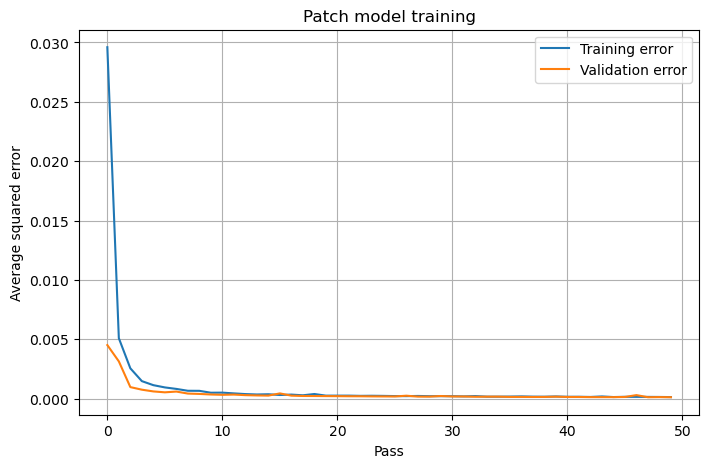

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(train_errors, label="Training error")
plt.plot(val_errors, label="Validation error")
plt.xlabel("Pass")
plt.ylabel("Average squared error")
plt.title("Patch model training")
plt.legend()
plt.grid(True)
plt.savefig(FIGURE_DIR / "patch_training_error.png", bbox_inches="tight")
plt.show()

### 9. Build a heatmap for each validation photo

Load the saved model with the lowest validation error. For each validation photo, cut the same patches again, rebuild them, and measure the error at each pixel.

Each patch error is put back on the 256 by 256 photo. Where patches overlap, the errors are averaged. The result is one heatmap. Brighter areas are the places the model could not rebuild well.

These heatmaps are kept for notebook 04. Test labels and defect masks are still not used.

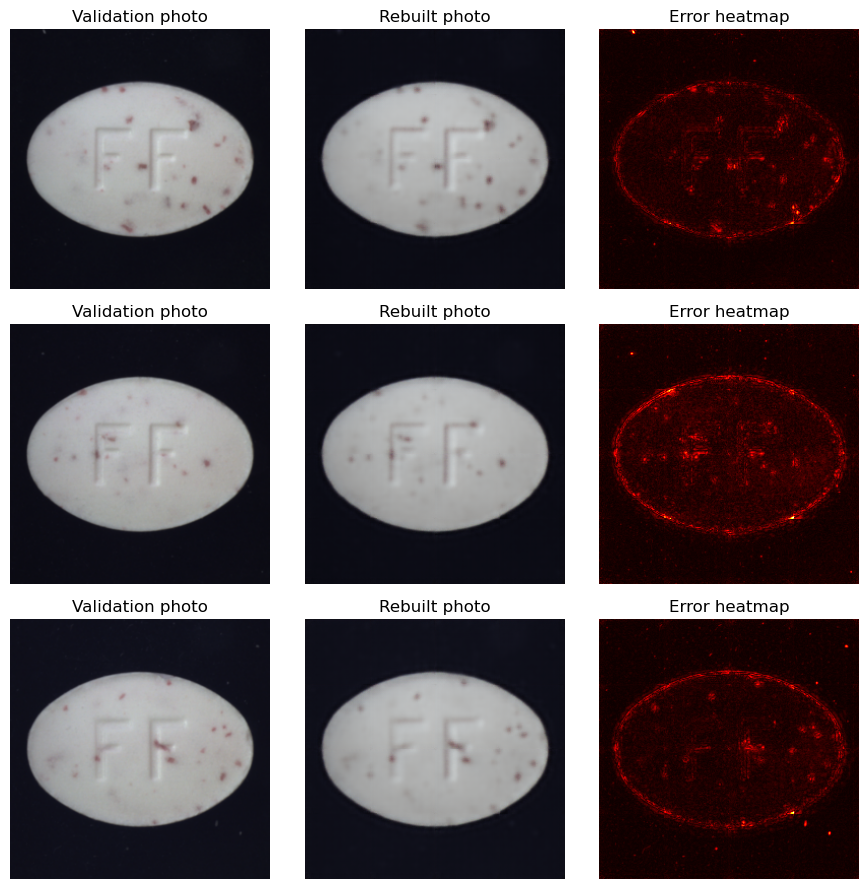

Heatmaps use validation photos only.
Background rule: Skip a patch when its average brightness is below 0.08 and its spread is below 0.05.


In [9]:
# The saved file holds the model numbers and a short note about the background rule.
try:
    saved = torch.load(checkpoint_path, map_location=device, weights_only=False)
except TypeError:
    saved = torch.load(checkpoint_path, map_location=device)
model.load_state_dict(saved["model_state"])
model.eval()


def error_map(image):
    # Add patch errors onto the photo, and count how many patches cover each pixel.
    total = torch.zeros(IMAGE_SIZE, IMAGE_SIZE)
    cover = torch.zeros(IMAGE_SIZE, IMAGE_SIZE)
    rebuilt_total = torch.zeros_like(image)
    with torch.no_grad():
        for top, left in POSITIONS:
            patch = image[:, top:top + PATCH_SIZE, left:left + PATCH_SIZE]
            if is_background(patch):
                continue
            rebuilt = model(patch.unsqueeze(0).to(device)).squeeze(0).cpu()
            pixel_error = torch.mean(torch.abs(rebuilt - patch), dim=0)
            total[top:top + PATCH_SIZE, left:left + PATCH_SIZE] += pixel_error
            cover[top:top + PATCH_SIZE, left:left + PATCH_SIZE] += 1
            rebuilt_total[:, top:top + PATCH_SIZE, left:left + PATCH_SIZE] += rebuilt
    heatmap = total / cover.clamp(min=1)
    heatmap[cover == 0] = 0
    rebuilt_image = rebuilt_total / cover.clamp(min=1)
    return heatmap, rebuilt_image


# Show three validation photos, the rebuilt photo, and the heatmap.
examples = min(3, len(val_paths))
figure, axes = plt.subplots(examples, 3, figsize=(9, 3 * examples))
if examples == 1:
    axes = [axes]

for row, relative_path in enumerate(val_paths[:examples]):
    image = load_resized(relative_path)
    heatmap, rebuilt_image = error_map(image)
    axes[row][0].imshow(image.permute(1, 2, 0))
    axes[row][0].set_title("Validation photo")
    axes[row][1].imshow(rebuilt_image.permute(1, 2, 0).clamp(0, 1))
    axes[row][1].set_title("Rebuilt photo")
    axes[row][2].imshow(heatmap, cmap="hot")
    axes[row][2].set_title("Error heatmap")
    for column in range(3):
        axes[row][column].axis("off")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "patch_validation_heatmaps.png", bbox_inches="tight")
plt.show()
print("Heatmaps use validation photos only.")
print("Background rule:", saved["background_rule"])